<a href="https://colab.research.google.com/github/mainapkago-pixel/course-project-GitHub-/blob/main/paul_maina_week_4_Assigment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Load the CSV dataset
Display the first five rows
  Station ID   County       Region  PMS Price (KES/L)  AGO Price (KES/L)  \
0      ST001  Nairobi      Nairobi              185.5              172.3   
1      ST002   Kiambu      Central              184.8              171.9   
2      ST003   Nakuru  Rift Valley              186.2              173.1   
3      ST004  Mombasa        Coast              183.7              170.8   
4      ST005   Kisumu      Western              184.9              172.0   

  Tank Condition Fire Extinguishers Drainage Earthing Spill Kit Compliant  
0           Good                Yes      Yes      Yes       Yes       Yes  
1           Good                Yes      Yes      Yes       Yes       Yes  
2           Good                Yes       No      Yes       Yes        No  
3           Good                Yes      Yes      Yes       Yes       Yes  
4           Fair                Yes      Yes       No       Yes        No  
Calculate descriptive statistics
Selec

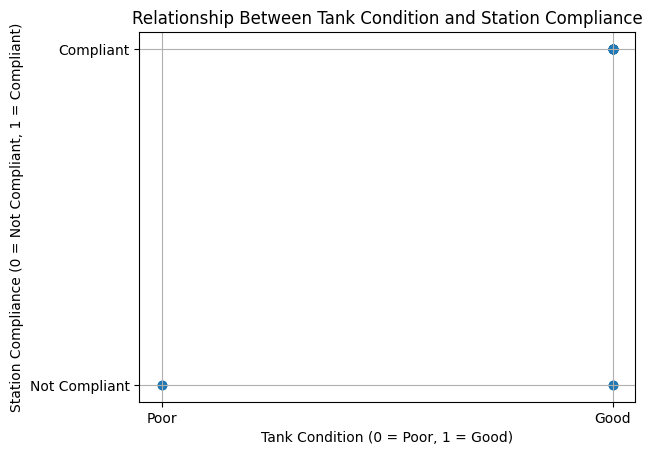

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

print("Load the CSV dataset")
data = pd.read_csv("/stations data.csv")

print("Display the first five rows")
print(data.head())

print("Calculate descriptive statistics")

print("Select only numerical columns to calculate statistics")

print("Select the final column using the correct variable 'data'")

compliance = data.iloc[:, -1].astype(str).str.strip().str.lower()

compliance = compliance.map({
    'yes': 1,
    'no': 0
})

print("Calculate the statistics")
print("Mean:", compliance.mean())
print("Median:", compliance.median())
print("Range:", compliance.max() - compliance.min())
print("Variance:", compliance.var())
print("Standard Deviation:", compliance.std())

print("Calculate overall compliance percentage")
print("Compliance Percentage:", compliance.mean() * 100, "%")

print("Select the Tank Condition column")
tank = data['Tank Condition'].astype(str).str.strip().str.lower()

# Convert tank condition into numbers
tank = tank.map({
    'good': 1,
    'poor': 0
})

tank = tank.dropna()

print("Calculate statistics")
print("Tank Condition Statistics")
print("Mean:", tank.mean())
print("Median:", tank.median())
print("Range:", tank.max() - tank.min())
print("Variance:", tank.var())
print("Standard Deviation:", tank.std())

# Calculate percentage of tanks in good condition
print("Percentage of tanks in good condition:", tank.mean() * 100, "%")

# Align both series to ensure they have matching indices
test_data = pd.concat([tank, compliance], axis=1, join='inner')
test_data.columns = ['Tank Condition', 'Compliance']

# Calculate covariance and correlation
covariance = test_data['Tank Condition'].cov(test_data['Compliance'])
correlation = test_data['Tank Condition'].corr(test_data['Compliance'])

# Display results
print("Covariance:", round(covariance, 3))
print("Correlation:", round(correlation, 3))

# Create a scatter plot
plt.scatter(test_data['Tank Condition'], test_data['Compliance'])

# Add labels and title
plt.xlabel('Tank Condition (0 = Poor, 1 = Good)')
plt.ylabel('Station Compliance (0 = Not Compliant, 1 = Compliant)')
plt.title('Relationship Between Tank Condition and Station Compliance')

# Display the plot
plt.xticks([0, 1], ['Poor', 'Good'])
plt.yticks([0, 1], ['Not Compliant', 'Compliant'])
plt.grid(True)
plt.show()

The mean, median, range, variance, and standard deviation summarize the data and show the distribution and variation of the observations. The correlation coefficient indicates the strength and direction of the relationship between tank condition and station compliance. A positive correlation means better tank condition tends to be associated with station compliance, while a negative correlation indicates an opposite relationship. However, correlation does not necessarily mean causation because other factors may influence station compliance.